<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5b_dualcomplexos_sistemas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V (b): sistemas de equações com poses

## Cinemática inversa de um braço articulado, e alinhar dois scans de um robô (ICP)

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 5](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb)) · **Anterior:** [X5a_dualcomplexos_algebra.ipynb](X5a_dualcomplexos_algebra.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5a_dualcomplexos_algebra.ipynb)) · **Próximo:** [X5c_dualcomplexos_edo.ipynb](X5c_dualcomplexos_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5c_dualcomplexos_edo.ipynb))

**Objetivo.** Dois problemas clássicos em que a incógnita é uma pose, ou uma cadeia de poses:
- **cinemática inversa:** quais ângulos de junta levam a mão de um braço articulado a um ponto (ou a uma pose) dado? É um sistema não linear com **várias soluções** (cotovelo para cima ou para baixo), **singularidades** (o braço esticado) e, com juntas sobrando, **infinitas soluções**. O jacobiano sai por números duais passando pela cadeia de dual-complexos;
- **alinhar dois *scans*:** um robô mede com um LiDAR os pontos das paredes à sua volta, anda, e mede de novo. Qual pose leva um *scan* ao outro? Com os pares de pontos conhecidos, há uma solução fechada de uma linha em notação complexa. Sem eles, o ICP (*iterative closest point*) alterna entre adivinhar os pares e resolver, e pode cair em mínimos locais.

**Roteiro**
1. O braço de dois segmentos: duas soluções, Newton com jacobiano dual e as bacias de atração
2. Singularidades e alvos fora de alcance
3. Três segmentos: alcançar uma pose, e juntas sobrando
4. Alinhar dois *scans* com os pares conhecidos: a solução fechada
5. O ICP: sem os pares, e os mínimos locais
6. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

from scipy.spatial import cKDTree
rng = np.random.default_rng(52)

class Dual:
    """Número dual re + ε·du (notebook III(a)); re e du podem ser floats ou arrays."""
    __array_priority__ = 1000
    def __init__(self, re, du=0.0): self.re, self.du = re, du
    @staticmethod
    def _d(o): return o if isinstance(o, Dual) else Dual(o, 0.0)
    def __add__(self, o): o = Dual._d(o); return Dual(self.re + o.re, self.du + o.du)
    __radd__ = __add__
    def __neg__(self): return Dual(-self.re, -self.du)
    def __sub__(self, o): return self + (-Dual._d(o))
    def __rsub__(self, o): return Dual._d(o) - self
    def __mul__(self, o): o = Dual._d(o); return Dual(self.re * o.re, self.re * o.du + self.du * o.re)
    __rmul__ = __mul__
    def __truediv__(self, o): o = Dual._d(o); return Dual(self.re / o.re, (self.du * o.re - self.re * o.du) / o.re**2)
    def __rtruediv__(self, o): return Dual._d(o) / self
    def __repr__(self): return f"{self.re} + ε·{self.du}"

def _eleva(f, df):
    return lambda x: Dual(f(x.re), df(x.re) * x.du) if isinstance(x, Dual) else f(x)
sen = _eleva(np.sin, np.cos)
cos = _eleva(np.cos, lambda a: -np.sin(a))

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))


def mao_xy(q):
    """Posição (x, y) da translação de um dual-complexo unitário, com aritmética real (funciona com duais)."""
    return 2 * (q.b0 * q.a0 - q.b1 * q.a1), 2 * (q.b0 * q.a1 + q.b1 * q.a0)

def junta(theta, ell):
    """Girar θ e depois andar ℓ para a frente, com θ possivelmente dual.
    A translação é t = ℓ e^{iθ}, e b = t r̄ / 2 = ℓ r / 2, com r = cos(θ/2) + i sen(θ/2)."""
    c_, s_ = cos(theta * 0.5), sen(theta * 0.5)
    return DC(c_, s_, c_ * (ell / 2), s_ * (ell / 2))

---

## 1. O braço de dois segmentos

Um braço com segmentos de $\ell_1=1$ e $\ell_2=0{,}8$, com a base na origem. A mão está em $q_1q_2$, com $q_k$ = "girar $\theta_k$ e andar $\ell_k$" (notebook V(a), seção 4). Para alcançar o alvo $\mathbf p^\star$, é preciso resolver duas equações em $(\theta_1,\theta_2)$:

$$\mathbf g(\theta_1,\theta_2)=\mathrm{posição}(q_1q_2)-\mathbf p^\star=\mathbf 0 .$$

**A solução fechada** vem da lei dos cossenos: $\cos\theta_2=\dfrac{\lvert\mathbf p^\star\rvert^2-\ell_1^2-\ell_2^2}{2\ell_1\ell_2}$, com **duas** soluções, $\pm\theta_2$: o cotovelo para cima e o cotovelo para baixo. Com mais segmentos, ou com segmentos que não estão no mesmo plano, fórmulas assim deixam de existir, e o caminho geral é o Newton.

**O jacobiano por números duais.** A função `junta` constrói o dual-complexo com $\cos(\theta/2)$ e $\sin(\theta/2)$, que funcionam com números duais (notebook III(a)). Passando $\theta_1+\varepsilon$, a cadeia inteira carrega a derivada, e a posição da mão sai com a coluna 1 do jacobiano na parte dual. Duas passadas dão o jacobiano $2\times2$. E as partes real e dual podem ser **arrays**: o mesmo código calcula o jacobiano para milhares de configurações de uma vez.

In [2]:
L1, L2 = 1.0, 0.8

def mao(th1, th2):
    return mao_xy(junta(th1, L1) * junta(th2, L2))

def jacobiano(th1, th2):
    """J[i][j] = ∂(posição i)/∂θ_j, por duais; funciona com arrays de configurações."""
    x1, y1 = mao(Dual(th1, 1.0), Dual(th2, 0.0))
    x2, y2 = mao(Dual(th1, 0.0), Dual(th2, 1.0))
    return np.array([[x1.du, x2.du], [y1.du, y2.du]])

th_t = (0.7, 1.1)
J_formula = np.array([[-L1 * np.sin(th_t[0]) - L2 * np.sin(sum(th_t)), -L2 * np.sin(sum(th_t))],
                      [L1 * np.cos(th_t[0]) + L2 * np.cos(sum(th_t)), L2 * np.cos(sum(th_t))]])
confere("jacobiano dual = derivada da fórmula", jacobiano(*th_t), J_formula, tol=1e-15)

def newton_braco(th, alvo, n=50, tol=1e-13):
    th = np.array(th, float)
    for it in range(n):
        x, y = mao(*th)
        x, y = (x.re, y.re) if isinstance(x, Dual) else (x, y)
        g = np.array([x - alvo.real, y - alvo.imag])
        d = np.linalg.solve(jacobiano(*th), -g)
        th = th + d
        if np.linalg.norm(d) < tol:
            return th, it + 1
    return th, None

alvo = 1.2 + 0.6j
c2 = (abs(alvo)**2 - L1**2 - L2**2) / (2 * L1 * L2)
sol_fechadas = []
for sinal in (+1, -1):
    t2 = sinal * np.arccos(c2)
    t1 = np.angle(alvo) - np.arctan2(L2 * np.sin(t2), L1 + L2 * np.cos(t2))
    sol_fechadas.append(np.array([t1, t2]))
for chute in ([0.0, 1.0], [1.0, -1.0]):
    th, it = newton_braco(chute, alvo)
    qual = int(np.argmin([np.linalg.norm(np.angle(np.exp(1j * (th - s)))) for s in sol_fechadas]))
    print(f"chute {chute}: θ = {np.degrees(th).round(3)}°  em {it} iterações  → cotovelo {'para baixo' if sol_fechadas[qual][1] > 0 else 'para cima'}")
    confere("  igual à solução fechada", np.angle(np.exp(1j * (th - sol_fechadas[qual]))), [0, 0], tol=1e-12)

OK   jacobiano dual = derivada da fórmula:  diferença máxima = 2.22e-16
chute [0.0, 1.0]: θ = [-9.826 84.261]°  em 6 iterações  → cotovelo para baixo
OK     igual à solução fechada:  diferença máxima = 5.55e-17
chute [1.0, -1.0]: θ = [ 62.956 -84.261]°  em 6 iterações  → cotovelo para cima
OK     igual à solução fechada:  diferença máxima = 6.66e-16


**As bacias de atração.** Qual das duas soluções o Newton encontra? A célula parte de uma grade de $200\times200$ chutes $(\theta_1,\theta_2)$ e roda o Newton **vetorizado**: os arrays de ângulos entram nos duais, e cada iteração resolve 40 000 sistemas $2\times2$ de uma vez (pela regra de Cramer). O desenho é periódico nos dois ângulos (uma volta inteira em qualquer junta dá o mesmo braço).

cotovelo para baixo (θ₂ > 0)  :  49.3% dos chutes
cotovelo para cima (θ₂ < 0)   :  48.6% dos chutes
não convergiu                 :   2.1% dos chutes


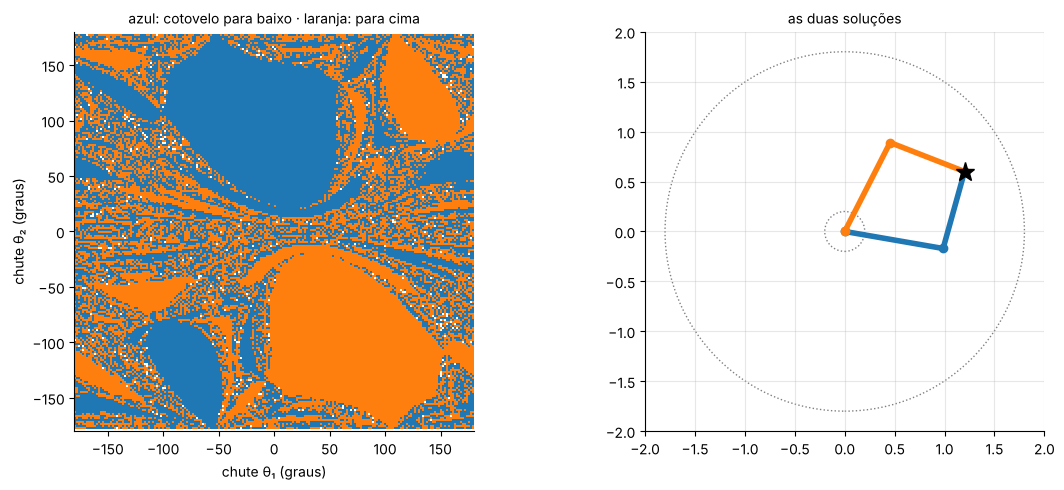

In [3]:
n_g = 200
T1, T2 = np.meshgrid(np.linspace(-np.pi, np.pi, n_g), np.linspace(-np.pi, np.pi, n_g))
th1, th2 = T1.ravel().copy(), T2.ravel().copy()
with np.errstate(all="ignore"):
    for it in range(40):
        x, y = mao(th1, th2)
        J = jacobiano(th1, th2)
        g1, g2 = x - alvo.real, y - alvo.imag
        det = J[0, 0] * J[1, 1] - J[0, 1] * J[1, 0]
        d1 = (-g1 * J[1, 1] + g2 * J[0, 1]) / det
        d2 = (-g2 * J[0, 0] + g1 * J[1, 0]) / det
        th1, th2 = th1 + d1, th2 + d2
    x, y = mao(th1, th2)
    resid = np.hypot(x - alvo.real, y - alvo.imag)
classe = np.full(th1.shape, 2)
ok = resid < 1e-9
cot = np.angle(np.exp(1j * th2))
classe[ok & (cot > 0)] = 0
classe[ok & (cot < 0)] = 1
for k, nome in enumerate(["cotovelo para baixo (θ₂ > 0)", "cotovelo para cima (θ₂ < 0)", "não convergiu"]):
    print(f"{nome:30s}: {100 * np.mean(classe == k):5.1f}% dos chutes")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
cmap = plt.matplotlib.colors.ListedColormap(["tab:blue", "tab:orange", "white"])
ax[0].imshow(classe.reshape(n_g, n_g), origin="lower", extent=[-180, 180, -180, 180], cmap=cmap, vmin=-0.5, vmax=2.5, interpolation="nearest")
ax[0].set_xlabel("chute θ₁ (graus)"); ax[0].set_ylabel("chute θ₂ (graus)"); ax[0].grid(False)
ax[0].set_title("azul: cotovelo para baixo · laranja: para cima", fontsize=10)
for s, cor in zip(sol_fechadas, ["tab:blue", "tab:orange"]):
    pts = [0, L1 * np.exp(1j * s[0]), L1 * np.exp(1j * s[0]) + L2 * np.exp(1j * s.sum())]
    ax[1].plot([p.real for p in pts], [p.imag for p in pts], "-o", lw=4, color=cor)
ax[1].plot(alvo.real, alvo.imag, "k*", ms=14); ax[1].set_aspect("equal"); ax[1].set_title("as duas soluções", fontsize=10)
ax[1].add_patch(plt.Circle((0, 0), L1 + L2, fill=False, ls=":", color="gray")); ax[1].add_patch(plt.Circle((0, 0), L1 - L2, fill=False, ls=":", color="gray"))
ax[1].set_xlim(-2, 2); ax[1].set_ylim(-2, 2)
plt.tight_layout(); plt.show()

**Leitura.** Cada solução tem uma bacia grande, em volta dela, e as duas ocupam quase metade dos chutes cada (2% não convergem em 40 iterações). Mas há muita mistura: perto das linhas em que o jacobiano é singular ($\theta_2=0$ ou $\pm180°$, o braço esticado ou dobrado sobre si mesmo), as bacias se entrelaçam em faixas finas, porque o primeiro passo de Newton é enorme e joga o chute para qualquer lugar. É o mesmo fenômeno do fractal de Newton (notebook IV(b)), num problema de robótica. Os círculos pontilhados à direita delimitam o **espaço de trabalho**: a mão só alcança pontos entre $\ell_1-\ell_2$ e $\ell_1+\ell_2$ da base.

---

## 2. Singularidades e alvos fora de alcance

O determinante do jacobiano é $\ell_1\ell_2\sin\theta_2$: zero com o braço esticado ou dobrado. Perto dessas configurações, o sistema é **mal condicionado**: para mover a mão um pouco na direção "para fora", as juntas precisam girar muito. A célula leva o alvo para cada vez mais perto da borda do espaço de trabalho e mede o número de condição do jacobiano na solução e o número de iterações do Newton.

E se o alvo estiver **fora** do alcance? O sistema não tem solução, e o Newton não converge. O que faz sentido pedir é a configuração que deixa a mão **o mais perto possível** do alvo: um problema de mínimos quadrados (notebook I(b), seção 5), que aqui leva o braço a esticar-se na direção do alvo.

In [4]:
print(" distância do alvo à borda     κ(J) na solução   iterações de Newton")
for folga in [0.5, 0.1, 1e-2, 1e-4, 1e-6]:
    alvo_b = (L1 + L2 - folga) * np.exp(0.4j)
    th, it = newton_braco([0.3, 0.8], alvo_b)
    print(f"{folga:22.0e}   {np.linalg.cond(jacobiano(*th)):16.1e}   {it}")

def gauss_newton_braco(th, alvo, n=2000):
    """Mínimos quadrados com Levenberg–Marquardt: (JᵀJ + λI) d = −Jᵀg, com λ que cresce quando o passo piora.
    (Na solução, o braço está esticado e o jacobiano é singular: o passo de Gauss–Newton puro explode.)"""
    th = np.array(th, float); lam = 1e-2
    custo = lambda th: abs(complex(*mao(*th)) - alvo)**2
    for _ in range(n):
        x, y = mao(*th)
        g = np.array([x - alvo.real, y - alvo.imag]); J = jacobiano(*th)
        d = np.linalg.solve(J.T @ J + lam * np.eye(2), -J.T @ g)
        if custo(th + d) < custo(th):
            th, lam = th + d, lam / 3
        else:
            lam *= 3
        if np.linalg.norm(d) < 1e-13:
            break
    return th

longe = 2.5 * np.exp(0.9j)
th_n, it_n = newton_braco([0.3, 0.8], longe)
th_gn = gauss_newton_braco([0.3, 0.8], longe)
x, y = mao(*th_gn)
print(f"\nalvo a 2,5 m (alcance de 1,8 m): Newton {'convergiu' if it_n else 'não convergiu'};  Levenberg–Marquardt para em θ = {np.degrees(wrap(th_gn)).round(4)}°")
print(f"   mão em ({x:.4f}, {y:.4f}), a {abs(x + 1j * y - longe):.4f} m do alvo")
confere("Levenberg–Marquardt estica o braço (θ₂ → 0) na direção do alvo", [np.angle(np.exp(1j * th_gn[1])), np.angle(np.exp(1j * (th_gn[0] - np.angle(longe))))], [0, 0], tol=1e-5)
confere("a mão fica a 2,5 − 1,8 = 0,7 m do alvo", abs(complex(x, y) - longe), 0.7, tol=1e-9)

 distância do alvo à borda     κ(J) na solução   iterações de Newton
                 5e-01            2.5e+00   6
                 1e-01            6.9e+00   6
                 1e-02            2.3e+01   8
                 1e-04            2.3e+02   11
                 1e-06            2.3e+03   15

alvo a 2,5 m (alcance de 1,8 m): Newton não convergiu;  Levenberg–Marquardt para em θ = [51.5662 -0.    ]°
   mão em (1.1189, 1.4100), a 0.7000 m do alvo
OK   Levenberg–Marquardt estica o braço (θ₂ → 0) na direção do alvo:  diferença máxima = 2.34e-09
OK   a mão fica a 2,5 − 1,8 = 0,7 m do alvo:  diferença máxima = 3.33e-16


**Leitura.** Com o alvo a meio metro da borda, o jacobiano é bem condicionado e o Newton converge em poucas iterações. À medida que o alvo se aproxima da borda, $\kappa(\mathbf J)$ cresce como $1/\sqrt{\text{folga}}$ (perto da borda, $\theta_2$ é da ordem de $\sqrt{\text{folga}}$), e o Newton precisa de mais iterações. Fora de alcance, o Newton não converge, e os mínimos quadrados dão a resposta razoável: o braço esticado, apontando para o alvo, a $2{,}5-1{,}8=0{,}7$ m dele. Mas o Gauss–Newton puro não serve: na solução o braço está esticado, o jacobiano é singular, e o passo explode (na preparação deste notebook, ele terminou com ângulos de dezenas de milhares de graus e a mão do lado oposto). A célula usa o **Levenberg–Marquardt**, que soma $\lambda\mathbf I$ a $\mathbf J^\top\mathbf J$ e ajusta $\lambda$ conforme o passo melhora ou piora: perto da singularidade, ele se comporta como uma descida de gradiente cautelosa.

---

## 3. Três segmentos: alcançar uma pose, e juntas sobrando

**Alcançar uma pose.** Com três segmentos ($\ell_3=0{,}5$), o braço tem três juntas, e pode-se pedir posição **e** orientação da mão: três equações, três incógnitas. A orientação da mão é $\theta_1+\theta_2+\theta_3$, e o resíduo é

$$\mathbf g(\boldsymbol\theta)=\big(x-x^\star,\ y-y^\star,\ \mathrm{wrap}(\theta_1+\theta_2+\theta_3-\varphi^\star)\big).$$

**Juntas sobrando.** Pedindo só a posição, há três incógnitas e duas equações: em geral, **infinitas** soluções (o braço pode "se acomodar" de muitas maneiras com a mão parada). O jacobiano é $2\times3$, e o passo de Newton usa a **pseudoinversa**: entre todos os passos que zeram o resíduo linearizado, o de menor norma (`np.linalg.lstsq` faz isso). Cada chute leva a uma solução diferente.

OK   pose alcançada: posição:  diferença máxima = 6.45e-15
OK   pose alcançada: orientação:  diferença máxima = 1.73e-14


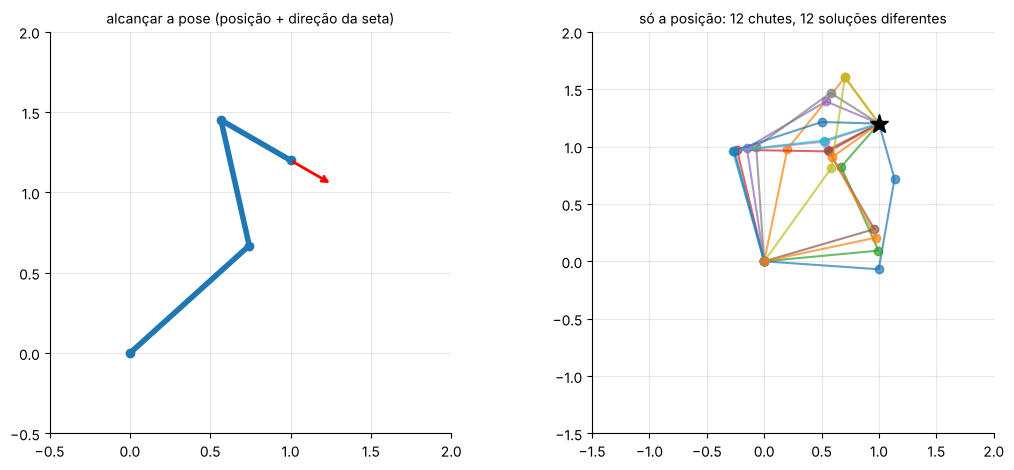

orientações da mão nas soluções só de posição (graus): [105.7 -53.6  48.7  29.  -22.7  27.2  18.4 -32.4 -53.6  17.2  -1.6  35.6]


In [5]:
L3 = 0.5
def mao3(th):
    q = junta(th[0], L1) * junta(th[1], L2) * junta(th[2], L3)
    return mao_xy(q)

def jac3(th, linhas=3):
    cols = []
    for j in range(3):
        thd = [Dual(th[i], 1.0 if i == j else 0.0) for i in range(3)]
        x, y = mao3(thd)
        cols.append([x.du, y.du, 1.0][:linhas])            # ∂(θ1+θ2+θ3)/∂θ_j = 1
    return np.array(cols).T

def ik3(th, alvo, phi=None, n=100):
    th = np.array(th, float)
    for _ in range(n):
        x, y = mao3(th)
        g = [x - alvo.real, y - alvo.imag] + ([float(wrap(th.sum() - phi))] if phi is not None else [])
        d = np.linalg.lstsq(jac3(th, 3 if phi is not None else 2), -np.array(g), rcond=None)[0]
        th = th + d
        if np.linalg.norm(d) < 1e-13:
            break
    return th

alvo3, phi3 = 1.0 + 1.2j, np.radians(-30)
th_pose = ik3([0.5, 0.5, 0.5], alvo3, phi3)
x, y = mao3(th_pose)
confere("pose alcançada: posição", x + 1j * y, alvo3, tol=1e-12)
confere("pose alcançada: orientação", wrap(th_pose.sum() - phi3), 0, tol=1e-12)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
def desenha_braco(ax, th, **kw):
    pts = [0j]; ang = 0.0
    for t_, l in zip(th, [L1, L2, L3]):
        ang += t_; pts.append(pts[-1] + l * np.exp(1j * ang))
    ax.plot([p.real for p in pts], [p.imag for p in pts], "-o", **kw)
desenha_braco(ax[0], th_pose, lw=4, color="tab:blue")
d_ = 0.3 * np.exp(1j * phi3); ax[0].annotate("", xy=(alvo3.real + d_.real, alvo3.imag + d_.imag), xytext=(alvo3.real, alvo3.imag), arrowprops={"arrowstyle": "->", "lw": 2, "color": "r"})
ax[0].set_aspect("equal"); ax[0].set_xlim(-0.5, 2); ax[0].set_ylim(-0.5, 2); ax[0].set_title("alcançar a pose (posição + direção da seta)", fontsize=10)

sols = []
for _ in range(12):
    th = ik3(rng.uniform(-np.pi, np.pi, 3), alvo3)
    x, y = mao3(th)
    if abs(x + 1j * y - alvo3) < 1e-10:
        sols.append(th); desenha_braco(ax[1], th, lw=1.5, alpha=.7)
ax[1].plot(alvo3.real, alvo3.imag, "k*", ms=14); ax[1].set_aspect("equal"); ax[1].set_xlim(-1.5, 2); ax[1].set_ylim(-1.5, 2)
n_dif = len(np.unique(np.round(wrap(np.array(sols)), 4), axis=0))
ax[1].set_title(f"só a posição: {len(sols)} chutes, {n_dif} soluções diferentes", fontsize=10)
plt.tight_layout(); plt.show()
print("orientações da mão nas soluções só de posição (graus):", np.round(np.degrees(wrap(np.array([s.sum() for s in sols]))), 1))

**Leitura.** Com a orientação pedida, o Newton acha uma configuração que cumpre as três equações. Sem ela, cada chute leva a uma configuração diferente, todas com a mão no alvo, cada uma com a mão apontando para um lado: é a **redundância** dos braços com juntas sobrando. Os robôs industriais de sete juntas exploram isso para desviar de obstáculos com o cotovelo enquanto a mão faz o trabalho, escolhendo, entre as infinitas soluções, a que otimiza outro critério (o exercício 3 pede uma delas).

---

## 4. Alinhar dois *scans* com os pares conhecidos

Um robô mede com um LiDAR os pontos das paredes de uma sala, anda e mede de novo. No referencial do robô, os pontos do segundo *scan* são os do primeiro levados por uma pose desconhecida (o movimento do robô), mais ruído. Se soubermos **quais pontos se correspondem** ($p_k$ no primeiro *scan*, $w_k$ no segundo), o problema é

$$\min_{\theta,t}\ \sum_k\big\lvert e^{i\theta}p_k+t-w_k\big\rvert^2 .$$

**A solução fechada em notação complexa.** Centrando as duas nuvens nas suas médias ($\tilde p_k=p_k-\bar p$, $\tilde w_k=w_k-\bar w$), a translação some, e a rotação que minimiza a soma é a direção do número complexo

$$S=\sum_k\overline{\tilde p_k}\,\tilde w_k:\qquad e^{i\theta}=S/\lvert S\rvert,\qquad t=\bar w-e^{i\theta}\bar p .$$

É o problema de Procrustes (ou de Kabsch), que em 3D precisa de uma SVD; no plano, é um produto escalar complexo e um argumento. A célula confere com a SVD.

In [6]:
def sala(n_por_parede=60):
    """Uma sala em L (sem simetrias), amostrada nas paredes."""
    cantos = np.array([0, 8, 8 + 3j, 4 + 3j, 4 + 7j, 7j, 0])
    pts = [a + (b - a) * np.linspace(0, 1, n_por_parede, endpoint=False) for a, b in zip(cantos[:-1], cantos[1:])]
    return np.concatenate(pts)

def procrustes(p, w):
    pm, wm = p.mean(), w.mean()
    S = np.sum(np.conj(p - pm) * (w - wm))
    e_it = S / abs(S) if abs(S) > 0 else 1.0       # S = 0: todos os pares caíram no mesmo ponto (chute péssimo)
    return np.angle(e_it), wm - e_it * pm

def kabsch_svd(p, w):
    P = np.c_[p.real - p.real.mean(), p.imag - p.imag.mean()]; W = np.c_[w.real - w.real.mean(), w.imag - w.imag.mean()]
    U, _, Vt = np.linalg.svd(P.T @ W)
    D = np.diag([1, np.sign(np.linalg.det(Vt.T @ U.T))])
    Rm = Vt.T @ D @ U.T
    return np.arctan2(Rm[1, 0], Rm[0, 0])

P0 = sala()
th_v, t_v = np.radians(25), 1.5 - 0.8j
W0 = np.exp(1j * th_v) * P0 + t_v + 0.03 * (rng.standard_normal(len(P0)) + 1j * rng.standard_normal(len(P0)))
th_e, t_e = procrustes(P0, W0)
print(f"pose verdadeira: θ = {np.degrees(th_v):.3f}°, t = {t_v};   estimada: θ = {np.degrees(th_e):.3f}°, t = {t_e:.4f}")
confere("Procrustes complexo = SVD (Kabsch)", th_e, kabsch_svd(P0, W0), tol=1e-12)
confere("sem ruído, a pose sai exata", procrustes(P0, np.exp(1j * th_v) * P0 + t_v), (th_v, t_v), tol=1e-12)

pose verdadeira: θ = 25.000°, t = (1.5-0.8j);   estimada: θ = 25.033°, t = 1.5037-0.8017j
OK   Procrustes complexo = SVD (Kabsch):  diferença máxima = 3.33e-16
OK   sem ruído, a pose sai exata:  diferença máxima = 1.11e-15


---

## 5. O ICP: sem os pares, e os mínimos locais

Num LiDAR de verdade, ninguém diz qual ponto do segundo *scan* corresponde a qual do primeiro. O **ICP** (*iterative closest point*, Besl e McKay, 1992) alterna dois passos:
1. **adivinhar os pares:** cada ponto do primeiro *scan*, levado pela pose atual, faz par com o ponto **mais próximo** do segundo (uma árvore k-d acha os vizinhos depressa);
2. **resolver:** com esses pares, a pose sai da solução fechada da seção 4.

Cada iteração não aumenta a soma dos quadrados, e o método converge, mas para **algum** mínimo: se o chute inicial está longe, os pares adivinhados estão errados, e o ICP pode parar numa pose errada que encaixa as paredes de outro jeito. A célula mede a taxa de acerto em função do erro do chute inicial de ângulo. O segundo *scan* tem só 70% dos pontos (o robô não vê tudo de novo) e ruído de 3 cm.

chute a 15° e 0,6 m da verdade: ICP chega a θ = 24.946°, t = 1.502-0.798j em 23 iterações



erro inicial de ângulo: [5, 15, 30, 45, 60, 90, 120, 150, 180]
taxa de acerto:         ['1.00', '1.00', '1.00', '0.90', '0.50', '0.00', '0.00', '0.00', '0.35']


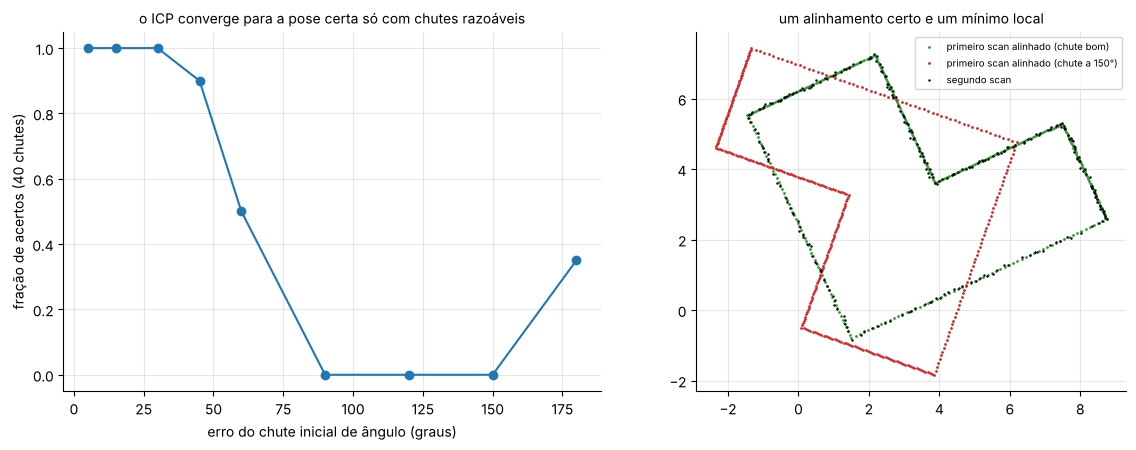

In [7]:
def icp(p, w, th0=0.0, t0=0j, n=60):
    arvore = cKDTree(np.c_[w.real, w.imag])
    th, t = th0, t0
    for it in range(n):
        pt = np.exp(1j * th) * p + t
        _, idx = arvore.query(np.c_[pt.real, pt.imag])
        th_n, t_n = procrustes(p, w[idx])
        if abs(wrap(th_n - th)) < 1e-12 and abs(t_n - t) < 1e-12:
            return th_n, t_n, it + 1
        th, t = th_n, t_n
    return th, t, n

visiveis = rng.random(len(P0)) < 0.7
W_scan = W0[visiveis]
th_i, t_i, it_i = icp(P0, W_scan, th0=np.radians(10), t0=1.0 - 0.5j)
print(f"chute a 15° e 0,6 m da verdade: ICP chega a θ = {np.degrees(th_i):.3f}°, t = {t_i:.3f} em {it_i} iterações")

erros_chute = [5, 15, 30, 45, 60, 90, 120, 150, 180]
taxa = []
for e_graus in erros_chute:
    acertos = 0
    for _ in range(40):
        sinal = rng.choice([-1, 1])
        th_c = th_v + sinal * np.radians(e_graus)
        t_c = t_v + 0.5 * complex(*rng.standard_normal(2))
        th_f, t_f, _ = icp(P0, W_scan, th_c, t_c)
        acertos += abs(wrap(th_f - th_v)) < np.radians(1) and abs(t_f - t_v) < 0.1
    taxa.append(acertos / 40)
print("\nerro inicial de ângulo:", erros_chute)
print("taxa de acerto:        ", [f"{x:.2f}" for x in taxa])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].plot(erros_chute, taxa, "o-"); ax[0].set_xlabel("erro do chute inicial de ângulo (graus)"); ax[0].set_ylabel("fração de acertos (40 chutes)")
ax[0].set_title("o ICP converge para a pose certa só com chutes razoáveis", fontsize=10)
th_ruim, t_ruim, _ = icp(P0, W_scan, th_v + np.radians(150), t_v)
for (th_, t_), cor, rot in [((th_i, t_i), "tab:green", "chute bom"), ((th_ruim, t_ruim), "tab:red", "chute a 150°")]:
    pt = np.exp(1j * th_) * P0 + t_
    ax[1].plot(pt.real, pt.imag, ".", ms=2, color=cor, label=f"primeiro scan alinhado ({rot})")
ax[1].plot(W_scan.real, W_scan.imag, "k.", ms=1.5, label="segundo scan")
ax[1].set_aspect("equal"); ax[1].legend(fontsize=7); ax[1].set_title("um alinhamento certo e um mínimo local", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** Com erros iniciais de ângulo de até 30°, o ICP acerta sempre; com 45°, quase sempre; com 60°, metade das vezes; com 90° a 150°, nunca. (Com 180°, uma parte dos chutes volta a acertar; entender por quê é o exercício 5.) Com chutes ruins, o ICP para em poses que encaixam algumas paredes nas paredes erradas (a figura mostra um desses mínimos locais, em vermelho). É o mesmo fenômeno das bacias de atração do Newton (notebook II(b) e seção 1 deste notebook), num problema em que o "chute" é uma pose. Na prática, o chute vem da odometria do robô, que costuma estar perto o bastante; e quando o robô se perde de vez, usam-se métodos globais (busca em grade de ângulos, descritores de forma) para achar um chute antes do ICP.

> **Nota: o elo com o SLAM.** Cada par de *scans* alinhados dá uma pose relativa entre dois instantes, com incerteza. Juntando todas essas poses relativas num grafo e corrigindo tudo de uma vez por mínimos quadrados no grupo, chega-se ao **SLAM por grafo de poses**, que está num apêndice deste domínio.

---

## 6. Exercícios

1. **Mais iterações perto da singularidade.** Na seção 2, troque o Newton puro por um Newton **amortecido** (Levenberg–Marquardt: $(\mathbf J^\top\mathbf J+\lambda\mathbf I)\,\mathbf d=-\mathbf J^\top\mathbf g$). O número de iterações perto da borda melhora? E o comportamento com o alvo fora de alcance?
2. **Bacias com três segmentos.** Desenhe as bacias da seção 3 (pose completa) num corte $\theta_3=0$. Quantas soluções há para a pose pedida?
3. **Redundância útil.** Com três segmentos e só a posição, acrescente ao passo de Newton um termo no **espaço nulo** do jacobiano, $(\mathbf I-\mathbf J^+\mathbf J)\,\mathbf z$, que empurra $\theta_2$ para zero (manter o cotovelo esticado). A mão continua no alvo?
4. **ICP ponto-reta.** Em vez de parear cada ponto com o ponto mais próximo, pareie com a **reta** da parede mais próxima (o ICP "ponto-a-plano", em 2D). Isso exige resolver um mínimos quadrados linearizado a cada iteração. Ele converge em menos iterações?
5. **Meia volta.** Na seção 5, por que alguns chutes com erro de 180° voltam a acertar? Desenhe a sala girada de meia volta sobre o segundo *scan*. Depois, troque a sala em L por um retângulo. Quantas poses diferentes alinham os dois *scans* igualmente bem? O que isso diz sobre localizar um robô num corredor?